In [32]:
import torch
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import Dataset, random_split
import torch.nn as nn


import scienceplots
plt.style.use(['science','notebook'])

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train")

Using cpu to train


In [33]:
def plot(x):
    plt.figure(figsize=(4,4))
    plt.imshow(x)
    plt.axis('auto')
    plt.xticks([0, x.shape[1] - 1])
    plt.yticks([0, x.shape[0] - 1])
    plt.show()

Generate data

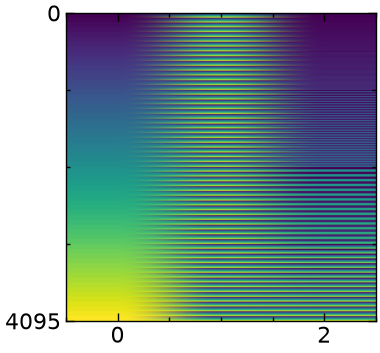

In [34]:
n = 64
data = np.zeros(shape=(n**2, 3))

def operation(i,j, n, op):
    if op == "mod_n":
        return (i + j) % n 
    elif op == "bitwise_and":
        return (i & j)
  
for i in range(n):
    for j in range(n):
        data[(i *n) + j] = [i, j, operation(i,j, n, "bitwise_and")]


plot(data)


Wrap dataset in a Dataset class
- `__init__` : init the dataset and convert from numpy to torch, ensuring its datatype is `long()`
- `__len__` : tells pytorch how many training examples exist
- `__getitem__`: take one row and separate inputs from answer 

In [35]:
class GrokkingDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = torch.from_numpy(dataset).long()

    def __len__(self):
        return self.dataset.shape[0]

    def __getitem__(self, idx):
        return self.dataset[idx, :2], self.dataset[idx, 2]

Split the dataset into train and test
- Get the indices to randomly split by 
- Split the dataset we created on those indices
- Here 40% goes to training, 60% to testing

In [36]:
dataset = GrokkingDataset(data)
train_indices, test_indices = random_split(dataset, [0.45, 0.55])

x_train, y_train = dataset[train_indices.indices]
x_test, y_test = dataset[test_indices.indices]

Create the Neural Network
- `__init__` : Setup the model layers
- `forward`  : Describe how the data should flow through the model


1. Our model converts each input number to a vector of length `embed_dimensions`
    - For example 3 -> [0.2, 0.3, -0.1, 0.8], *(here embed_dim = 4)*
    - We do this to give the model more features to work with
    - Our model can change what vector is associates with each number
    - In a language example it might learn that cat is a similar vector to dog
    - In our example, it might learn representations useful for learning the mathematical operation
2. We concatenate the two vectors into one longer vector:
    - Example if we give the model:
        - 3 -> [0.2, 0.3, -0.1, 0.8]
        - 4 -> [0.1, 0.3, 0.6, 0.4]
        - Concatenate : [0.2, 0.3, -0.1, 0.8, 0.1, 0.3, 0.6, 0.4]
        - Now, our vector has length embed_dim * 2 = 4 * 2 = 8
3. We feed our vector each hidden neuron, where we have `hidden_dimension` number of neurons
4. Each neuron preforms a weighted sum on the vector and produces an output 
5. We apply [ReLU](https://www.geeksforgeeks.org/deep-learning/relu-activation-function-in-deep-learning/), however we could apply many more [activation functions](https://en.wikipedia.org/wiki/Activation_function)
    - Activation functions introduce a non linearity, allowing our model to represent non linear relationships
6. Our relu'd outputs get send to `n` output neurons, where they produce a score
7. The highest score is the predicted number

In [37]:
class GrokkingModel(nn.Module):
    def __init__(self, embed_dimension, hidden_dimension, n):
        super().__init__()

        self.left_embed = nn.Embedding(n, embed_dimension)
        self.right_embed = nn.Embedding(n, embed_dimension)
        self.hidden = nn.Linear(2*embed_dimension, hidden_dimension, bias=False)
        self.relu = nn.ReLU()
        self.unembedding = nn.Linear(hidden_dimension, n, bias=False)


        nn.init.normal_(self.left_embed.weight, std=0.1)
        nn.init.normal_(self.right_embed.weight, std=0.1)


    def forward(self, input):
        a_embed = self.left_embed(input[:, 0])
        b_embed = self.right_embed(input[:, 1])

        x = torch.cat((a_embed,b_embed), dim=1)
        x = self.hidden(x)
        x = self.relu(x)
        logits = self.unembedding(x)
        return logits

In [38]:
def calculate_accuracy(logits, true_values):

    # Get our predictions
    predictions = logits.argmax(dim=1)

    # (predictions == true_values) returns an array True / False values depending if we predicted correctly
    # turn a float and get the average
    return (predictions == true_values).float().mean()

In [39]:
# Initialize the model
# For mod_n put hidden_dim = 256, embed_dim = 128, it needs more to work with
model = GrokkingModel(embed_dimension=6, hidden_dimension=6, n=n)

# Put the model and datasets on the correct device
model = model.to(device)

# Move datasets to the correct device
x_train = x_train.to(device)
y_train = y_train.to(device)

x_test = x_test.to(device)
y_test = y_test.to(device)

In [ ]:

# Maximum number of passes over the training data
epochs = 10_000


# Create an optimizer to update the models weights
optimizer = torch.optim.AdamW(model.parameters(), weight_decay=0.5)

# Create a loss function to score the models predictions
loss_func = nn.CrossEntropyLoss()

training_losses, test_losses = [], []
training_accuracies, test_accuracies = [], []


# Iterate over the dataset
for i in range(epochs):
    model.train()                       # Put the model in training mode
    optimizer.zero_grad()               # Clear the previous training steps gradients
    logits = model(x_train)             # Preict the entire training dataset 
    loss = loss_func(logits, y_train)   # Calculuate the loss / error of our prediction vs true values
    loss.backward()                     # Calculate the derivatives
    optimizer.step()                    # Update the weights according to the derivatives
    

    # Every 100th pass over the dataset
    if i % 100 == 0:
        model.eval()                                   # Put the model in evaluation mode so its doesnt update weights
        with torch.no_grad():                          # Disable derivative calculation
            test_logits = model(x_test)                # Predict the entire test dataset
            test_loss = loss_func(test_logits, y_test) # Calculate the loss for the test predictions vs true values


        # Record losses
        training_losses.append(loss.item())             
        test_losses.append(test_loss.item())

        # Record accuracy 
        train_accuracy = calculate_accuracy(logits, y_train)
        test_accuracy = calculate_accuracy(test_logits, y_test)

        training_accuracies.append(train_accuracy)
        test_accuracies.append(test_accuracy)

        # Print information
        print(f"Epoch {i : < 5} | Loss {loss : <6.3f} | Test loss {test_loss: <6.3f} | Train accuracy {train_accuracy : <6.3f} | Test accuracy {test_accuracy : <6.3f}")

        # Stop training when our model achieves 100% accuracy on the test data
        if test_accuracy == 1.0:
            break


Epoch  0    | Loss 4.159  | Test loss 4.160  | Train accuracy 0.012  | Test accuracy 0.008 
Epoch  100  | Loss 4.024  | Test loss 4.041  | Train accuracy 0.150  | Test accuracy 0.121 
Epoch  200  | Loss 3.295  | Test loss 3.386  | Train accuracy 0.183  | Test accuracy 0.161 
Epoch  300  | Loss 2.936  | Test loss 3.061  | Train accuracy 0.188  | Test accuracy 0.177 
Epoch  400  | Loss 2.719  | Test loss 2.870  | Train accuracy 0.206  | Test accuracy 0.188 
Epoch  500  | Loss 2.508  | Test loss 2.685  | Train accuracy 0.248  | Test accuracy 0.220 
Epoch  600  | Loss 2.316  | Test loss 2.505  | Train accuracy 0.293  | Test accuracy 0.267 
Epoch  700  | Loss 2.147  | Test loss 2.340  | Train accuracy 0.353  | Test accuracy 0.328 
Epoch  800  | Loss 1.987  | Test loss 2.185  | Train accuracy 0.405  | Test accuracy 0.379 
Epoch  900  | Loss 1.823  | Test loss 2.025  | Train accuracy 0.457  | Test accuracy 0.418 
Epoch  1000 | Loss 1.667  | Test loss 1.870  | Train accuracy 0.505  | Test accu

Plot test / train accuracy and loss every 100 epoch

Final test accuracy = 0.9933392405509949


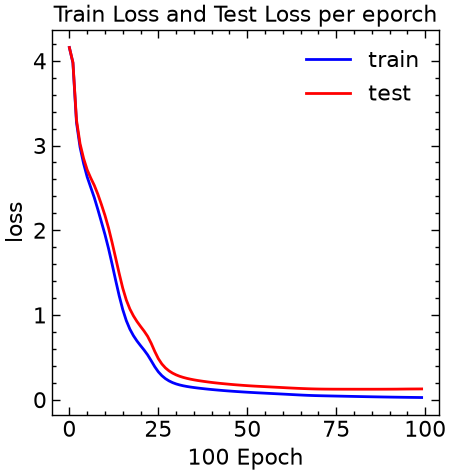

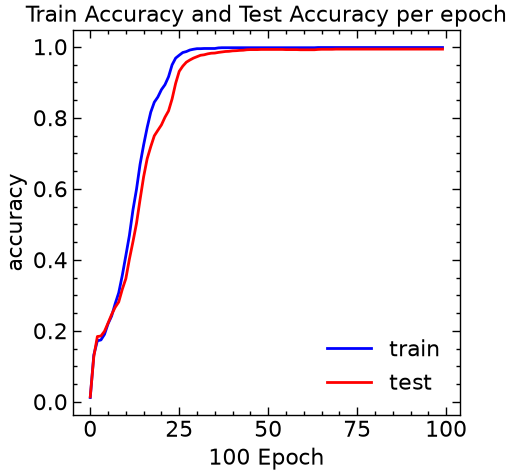

In [ ]:
def plot_metrics(train, test, title, ylabel):
    plt.figure(figsize=(5, 5))
    plt.title(title)
    plt.plot(train, c='b', label='train')
    plt.plot(test, c='r', label='test')

    plt.ylabel(ylabel)
    plt.xlabel('100 Epoch')
    plt.legend()
    plt.show()


print(f"Final test accuracy = {calculate_accuracy(model(x_test), y_test)}")
plot_metrics(training_losses, test_losses, 'Train Loss and Test Loss per eporch', 'loss')
plot_metrics(training_accuracies, test_accuracies, 'Train Accuracy and Test Accuracy per epoch', 'accuracy')



Look at the models internals

In [ ]:
def plot_activations(model, side, neuron, relu=False):
    left = model.left_embed.weight          # Left embedding matrix
    right = model.right_embed.weight        # Right embedding matrix
    hidden = model.hidden.weight            # Hidden layer matrix 

    length_of_each_vector = model.left_embed.weight.shape[1]

    # Get the activations for each possible left input
    left_pre_activations = torch.matmul(left, hidden[:, :length_of_each_vector].T)

    # Get the activations for each possible right input
    right_pre_activations = torch.matmul(right, hidden[:, length_of_each_vector:].T)

    
    if side == "left":
        values = left_pre_activations[:, neuron].detach()
    if side == "right":
        values = right_pre_activations[:, neuron].detach()
    if side == "both":
       values = left_pre_activations[:, neuron, None].detach() + right_pre_activations[None, :, neuron].detach()
        


    if relu == True:
        type = "activation"
        values = torch.relu(values)
    else:
        type = "preactivation"

    if side == "both":
        plt.figure(figsize=(5, 5))
        plt.imshow(values)
        plt.xlabel("a input")
        plt.ylabel("b input")
        plt.title(f"Nueron {neuron} {type} across all input pairs (a,b)")
    
    else:
        plt.figure(figsize=(30, 2))
        plt.plot(values)
        plt.title(f"{side} {type} for neuron {neuron}" )
        plt.xticks(np.arange(values.shape[0]))
        plt.xticks(rotation=-45)
        plt.ylabel("Preactivation value")
        plt.xlabel("Input number")

    plt.show();

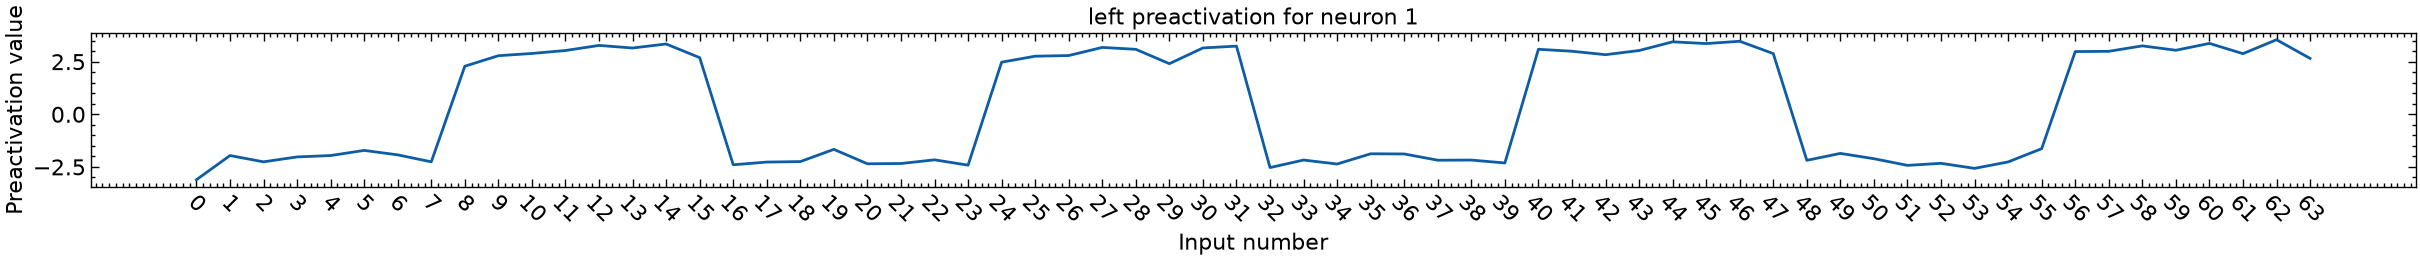

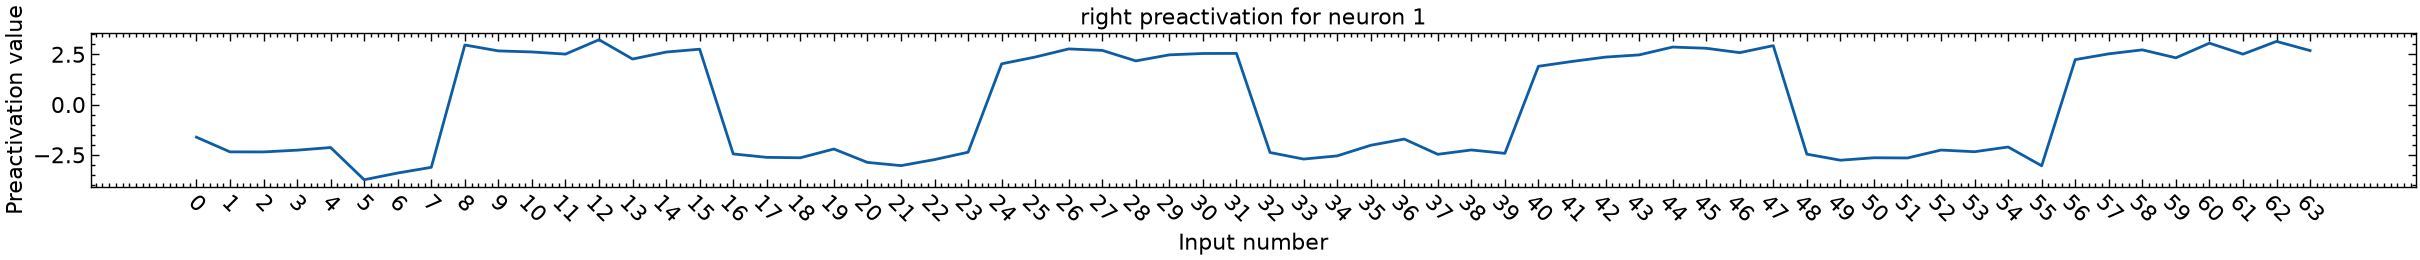

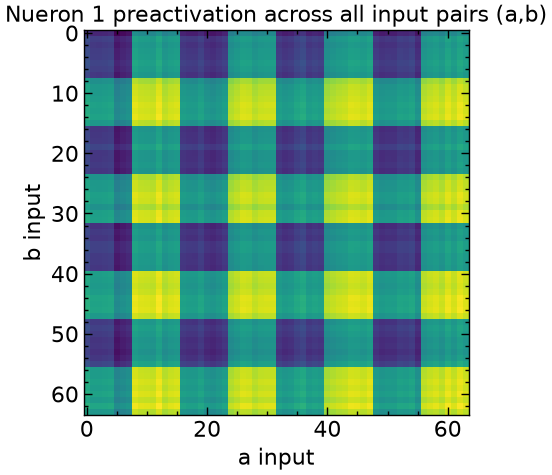

In [ ]:
nueron = 1

plot_activations(model, "left", nueron)
plot_activations(model, "right", nueron)
plot_activations(model, "both", nueron)



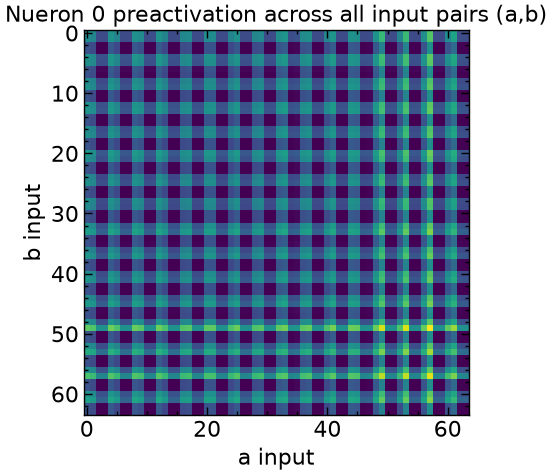

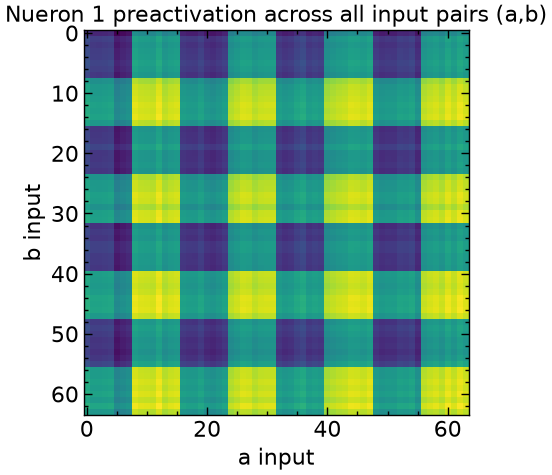

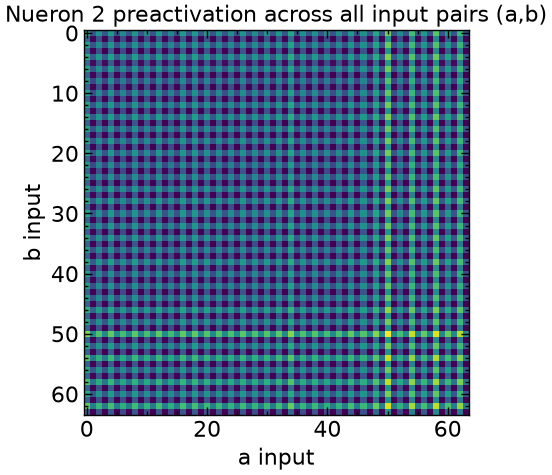

In [ ]:
plot_activations(model, "both", 0)
plot_activations(model, "both", 1)
plot_activations(model, "both", 2)